In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

import anndata as ad

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
train_data = sc.read_h5ad("../../input/diff_train.h5ad")
# print("train original data:", train_data)
# print(train_data.obs)
train_data.obs["day_types"] = train_data.obs["Group"]
# train_data.obs.loc[train_data.obs["day_types"] == 0, "weight_types"] = 0
# train_data.obs.loc[train_data.obs["day_types"] == 3, "weight_types"] = 1
train_data.obs["class_types"] = "1" 
# print(train_data.obs["weight_types"].unique())
print(train_data.obs["day_types"].unique())
print(train_data.obs_names)
# print(train_data.obs["cluster_types"].unique())

[3, 0]
Categories (2, int64): [3, 0]
Index(['25475_4#319-day3', '24229_5#259-day3', '25013_5#163-day3',
       '24539_1#53-day3', '25271_4#104-day3', '24539_1#197-day3',
       '24352_7#77-day3', '25579_2#223-day3', '24353_8#232-day3',
       '23794_3#349-day3',
       ...
       '24327_6#190-day0', '24475_7#242-day0', '24086_8#309-day0',
       '24475_3#377-day0', '22607_6#63-day0', '24252_5#250-day0',
       '25476_7#316-day0', '22139_6#121-day0', '24475_8#219-day0',
       '24229_3#217-day0'],
      dtype='object', length=2400)


In [3]:
test_data = sc.read_h5ad("../../input/diff_test.h5ad")
print("test original data:", test_data)

# print(train_data.obs)
test_data.obs["day_types"] = test_data.obs["Group"]
test_data.obs["class_types"] = "2"

# print(train_data.obs["weight_types"].unique())
print(test_data.obs["day_types"].unique())
print(test_data.obs_names)
# print(train_data.obs["cluster_types"].unique())


test original data: AnnData object with n_obs × n_vars = 2400 × 203
    obs: 'Group'
[1, 3, 0, 2]
Categories (4, int64): [1, 3, 0, 2]
Index(['24352_3#174-day1', '24722_6#134-day1', '24352_6#320-day1',
       '24539_8#342-day1', '24327_8#205-day1', '24352_3#322-day1',
       '22194_5#91-day1', '24722_8#270-day1', '24760_5#288-day1',
       '24722_6#139-day1',
       ...
       '24252_1#193-day2', '24252_1#160-day2', '24539_2#79-day2',
       '25262_3#150-day2', '21965_8#201-day2', '24252_1#352-day2',
       '25013_8#316-day2', '23794_4#39-day2', '21554_5#308-day2',
       '24539_5#164-day2'],
      dtype='object', length=2400)


In [4]:
# data_0 = sc.read_h5ad("../experiments/exp5_day0_predict_day0/interception_predict_to_day_0.h5ad")
# # data_0 = sc.read_h5ad("../experiments/squidiff_exp5_day0_predict_day1.h5ad")
# print(data_0)
# data_0.obs["day_types"] = 0
# print(data_0.obs["day_types"].unique())
# data_0.obs_names = [f"{i}-1-day0" for i in range(data_0.n_obs)]

data_1 = sc.read_h5ad("../experiments/exp5_day0_predict_day1/interception_predict_to_day_1.h5ad")
# data_1 = sc.read_h5ad("../experiments/squidiff_exp5_day0_predict_day1.h5ad")
print(data_1)
data_1.obs["day_types"] = 1
print(data_1.obs["day_types"].unique())
data_1.obs_names = [f"{i}-1-day1" for i in range(data_1.n_obs)]

data_2 = sc.read_h5ad("../experiments/exp5_day0_predict_day2/interception_predict_to_day_2.h5ad")
#data_2 = sc.read_h5ad("../experiments/squidiff_exp5_day0_predict_day1.h5ad")
print(data_2)
data_2.obs["day_types"] = 2
print(data_2.obs["day_types"].unique())
data_2.obs_names = [f"{i}-1-day2" for i in range(data_2.n_obs)]

# data_3 = sc.read_h5ad("../experiments/exp5_day0_predict_day3/interception_predict_to_day_3.h5ad")
# #data_3 = sc.read_h5ad("../experiments/squidiff_exp5_day0_predict_day1.h5ad")
# print(data_3)
# data_3.obs["day_types"] = 3
# print(data_3.obs["day_types"].unique())
# data_3.obs_names = [f"{i}-1-day3" for i in range(data_3.n_obs)]
# data = np.concatenate([data_1, data_3], axis=0)
data_celldiffgen = ad.concat([data_1, data_2], axis=0, join="inner")
# data_celldiffgen_2 = ad.concat([data_2, data_3], axis=0, join="inner")
# data_celldiffgen = ad.concat([data_celldiffgen_1, data_celldiffgen_2], axis=0, join="inner")
print(data_celldiffgen.shape)
data_celldiffgen.obs["day_types"] = pd.to_numeric(data_celldiffgen.obs["day_types"])
data_celldiffgen.obs["day_types"] = data_celldiffgen.obs["day_types"].astype("category")
# data.obs.loc[train_data.obs["day_types"] == 0, "weight_types"] = 0
data_celldiffgen.obs["class_types"] = "3" 
print(data_celldiffgen.obs["day_types"].unique())
print(data_celldiffgen)
# data.obs_names = [f"day{i + 1}" for i in range(data.n_obs)]
print(data_celldiffgen.obs_names)
data_celldiffgen.var_names = train_data.var_names
print(data_celldiffgen.var_names)
print(data_celldiffgen.var_names)

AnnData object with n_obs × n_vars = 600 × 203
[1]
AnnData object with n_obs × n_vars = 600 × 203
[2]
(1200, 203)
[1, 2]
Categories (2, int64): [1, 2]
AnnData object with n_obs × n_vars = 1200 × 203
    obs: 'day_types', 'class_types'
Index(['0-1-day1', '1-1-day1', '2-1-day1', '3-1-day1', '4-1-day1', '5-1-day1',
       '6-1-day1', '7-1-day1', '8-1-day1', '9-1-day1',
       ...
       '590-1-day2', '591-1-day2', '592-1-day2', '593-1-day2', '594-1-day2',
       '595-1-day2', '596-1-day2', '597-1-day2', '598-1-day2', '599-1-day2'],
      dtype='object', length=1200)
Index(['AASS', 'MPND', 'PRKCH', 'PNPLA6', 'VPS13D', 'NNAT', 'SLC2A3', 'GPBP1',
       'GAL', 'CLCN4',
       ...
       'COX5BP6', 'RPL32P26', 'RPS21P4', 'RPL35AP32', 'LEFTY1', 'HAUS5',
       'ECSCR', 'GYPB', 'PRSS2', 'VN1R81P'],
      dtype='object', length=203)
Index(['AASS', 'MPND', 'PRKCH', 'PNPLA6', 'VPS13D', 'NNAT', 'SLC2A3', 'GPBP1',
       'GAL', 'CLCN4',
       ...
       'COX5BP6', 'RPL32P26', 'RPS21P4', 'RPL35AP32'

In [5]:

interp_1 = ad.concat([train_data, test_data], axis=0, join="inner")
interp_all = ad.concat([interp_1, data_celldiffgen], axis=0, join="inner")
# interp_all = data_celldiffgen
# interp_all = test_data
print(interp_all)
#new start
interp_all.X = interp_all.X.astype("float64")
interp = interp_all.copy()
idx = interp.obs.sort_values(["day_types"]).index
print(idx)
interp_all = interp[idx].copy()
print(interp_all)
print(interp_all.obs["day_types"].unique())

AnnData object with n_obs × n_vars = 6000 × 203
    obs: 'day_types', 'class_types'
Index(['24475_5#84-day0', '25476_4#90-day0', '25619_7#326-day0',
       '23794_1#182-day0', '24475_5#340-day0', '24475_3#257-day0',
       '23794_1#104-day0', '25271_7#348-day0', '25619_7#130-day0',
       '25262_8#259-day0',
       ...
       '24539_7#113-day3', '24353_8#223-day3', '22607_8#263-day3',
       '22194_6#359-day3', '22710_2#157-day3', '24353_8#254-day3',
       '24352_7#235-day3', '25216_7#137-day3', '24539_7#57-day3',
       '25475_4#319-day3'],
      dtype='object', length=6000)
AnnData object with n_obs × n_vars = 6000 × 203
    obs: 'day_types', 'class_types'
[0, 1, 2, 3]
Categories (4, int64): [0, 1, 2, 3]


Cells × genes: (6000, 203)
AnnData object with n_obs × n_vars = 6000 × 203
    obs: 'day_types', 'class_types'
computing PCA
    with n_comps=50


    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:06)
computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         0.9866194  0.9532149  0.94550705 0.94517803 0.9365406
     0.9256329  0.9144267  0.87206674 0.86679894 0.8646941  0.85274696
     0.8391479  0.83244544 0.8275426 ]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running PAGA
    finished: added
    'paga/connectivities', conne

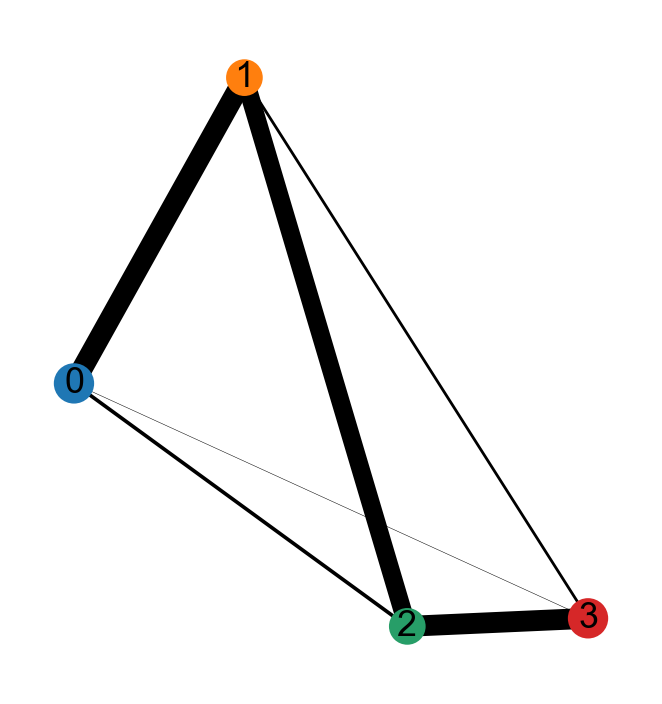

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:12)
Root cells: 1800
computing Diffusion Pseudotime using n_dcs=10
    finished: added
    'dpt_pseudotime', the pseudotime (adata.obs) (0:00:00)
24475_5#84-day0     0.000000
25476_4#90-day0     0.190135
25619_7#326-day0    0.054283
23794_1#182-day0    0.206144
24475_5#340-day0    0.021786
                      ...   
24353_8#254-day3    0.591994
24352_7#235-day3    0.694259
25216_7#137-day3    0.630679
24539_7#57-day3     0.508574
25475_4#319-day3    0.505948
Name: dpt_pseudotime, Length: 6000, dtype: float32


In [6]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

sc.settings.verbosity = 3
sc.settings.set_figure_params(
    dpi=100,
    frameon=False,
    figsize=(4, 4),
    facecolor="white"
)

interp_all_ann = interp_all.copy()
print("Cells × genes:", interp_all_ann.shape)

if "highly_variable" in interp_all_ann.var:
    print("Highly variable genes:",
          interp_all_ann.var["highly_variable"].sum())

# day_types used for PAGA trajectory
interp_all_ann.obs["day_types"] = pd.to_numeric(interp_all_ann.obs["day_types"])
interp_all_ann.obs["day_types"] = interp_all_ann.obs["day_types"].astype("category")
print(interp_all_ann)


# PCA
sc.tl.pca(interp_all_ann, svd_solver="arpack")

# sc.pp.neighbors(interp_all_ann, n_neighbors=15, n_pcs=30)
sc.pp.neighbors(interp_all_ann, n_neighbors=30, n_pcs=50)

sc.tl.diffmap(interp_all_ann)
sc.pp.neighbors(interp_all_ann)


# PAGA using day_types
sc.tl.paga(interp_all_ann, groups="day_types")

sc.pl.paga(
    interp_all_ann,
    color=["day_types"]
)

sc.tl.umap(interp_all_ann)


# Choose root from starting day
root_day = 0

root_mask = interp_all_ann.obs["day_types"] == root_day

print("Root cells:", root_mask.sum())

interp_all_ann.uns["iroot"] = np.flatnonzero(root_mask)[0]

# DPT pseudotime
sc.tl.dpt(interp_all_ann)
print(interp_all_ann.obs["dpt_pseudotime"])




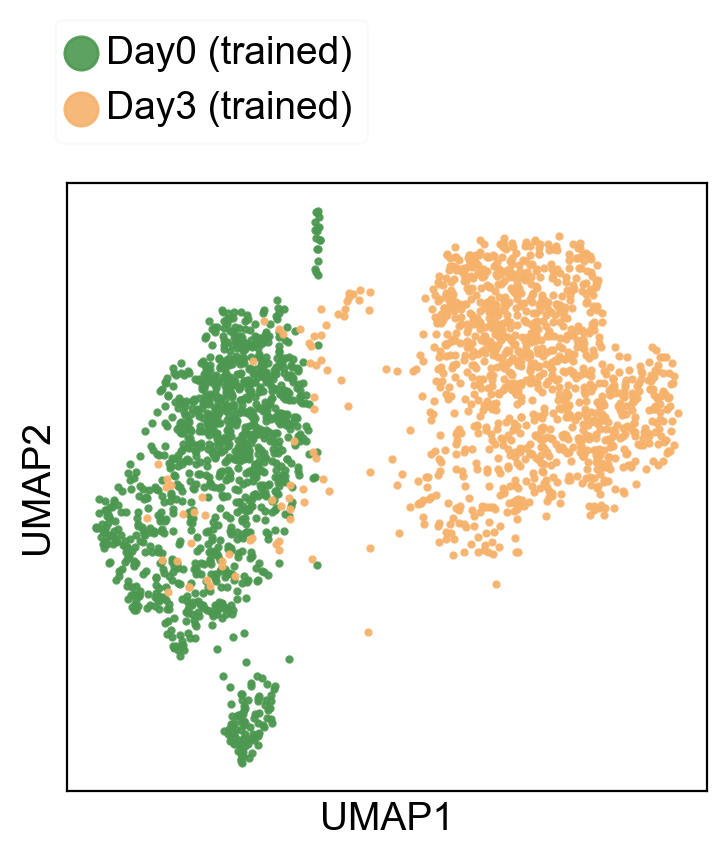

In [7]:

fig,ax = plt.subplots(figsize=(4.1, 4))
X_umap = interp_all_ann.obsm["X_umap"]

mask_0 = ((interp_all_ann.obs["day_types"] == 0) &
    (interp_all_ann.obs["class_types"] == "1"))
mask_3 = ((interp_all_ann.obs["day_types"] == 3) &
    (interp_all_ann.obs["class_types"] == "1"))

mask_ground_truth = interp_all_ann.obs["class_types"].isin(["2", "3"])

plt.scatter(
    X_umap[mask_0,0],
    X_umap[mask_0,1],
    c="#4C9850",
    s=4,
    alpha=0.9,
    label="Day0 (trained)"
)

plt.scatter(
    X_umap[mask_3,0],
    X_umap[mask_3,1],
    c="#F6B26B",
    s=4,
    alpha=0.9,
    label="Day3 (trained)"
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)
ax.set_xticks([])
ax.set_yticks([])
ax.legend(
    loc="upper right",
    bbox_to_anchor=(0.5, 1.3),
    markerscale=6,
    scatterpoints=1,
    prop={"size": 14, "weight": "bold"},
    frameon=True,
    facecolor="white",
    edgecolor="lightgray",
    framealpha=0.1
)
#plt.axis("off")
# plt.title("combined umap marked training data")
fig.savefig(os.path.join(f"figure1.pdf"), bbox_inches="tight")
plt.show()


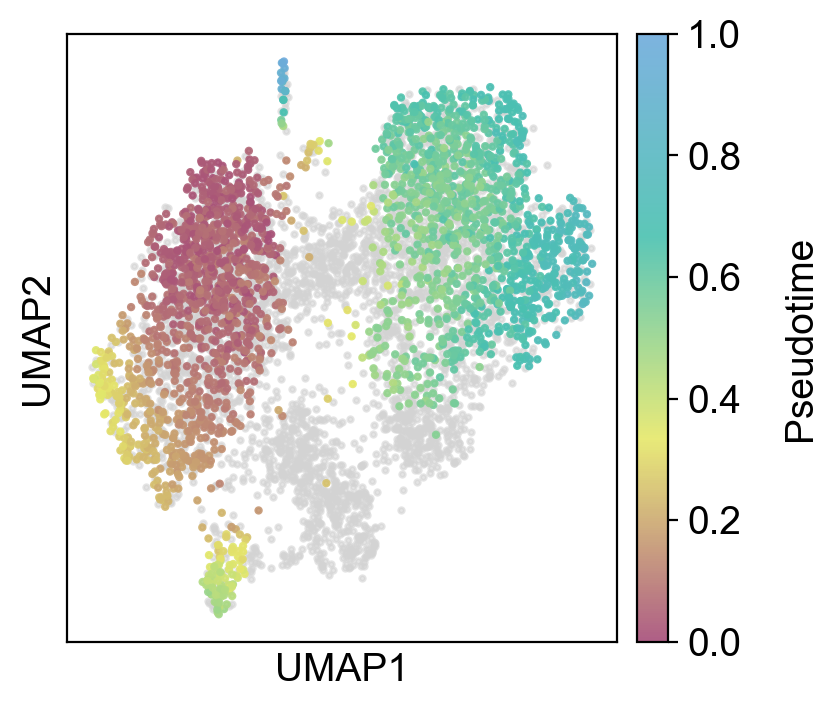

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(4.3, 4))

X_umap = interp_all_ann.obsm["X_umap"]
obs = interp_all_ann.obs

mask_0 = (obs["day_types"] == 0) & (obs["class_types"] == "1")
mask_3 = (obs["day_types"] == 3) & (obs["class_types"] == "1")
mask_show = (mask_0 | mask_3).to_numpy()

pseudotime = obs["dpt_pseudotime"].to_numpy()
mask_color = mask_show & np.isfinite(pseudotime)

my_cmap = LinearSegmentedColormap.from_list(
    "my_pseudotime",
    ["#A64D79", "#E6E86A", "#4AC1B0", "#6FABDC"]
)

# Other cells in gray
ax.scatter(
    X_umap[~mask_color, 0],
    X_umap[~mask_color, 1],
    c="lightgray",
    s=4,
    alpha=0.6
)

# Selected cells colored by pseudotime
points = ax.scatter(
    X_umap[mask_color, 0],
    X_umap[mask_color, 1],
    c=pseudotime[mask_color],
    cmap=my_cmap,
    vmin=0,
    vmax=1,
    s=4,
    alpha=0.9
)

cbar = fig.colorbar(points, ax=ax, pad=0.03)
cbar.set_label("Pseudotime", rotation=90, labelpad=15)

ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)

ax.set_xticks([])
ax.set_yticks([])

fig.savefig("figure2.pdf", bbox_inches="tight")
plt.show()

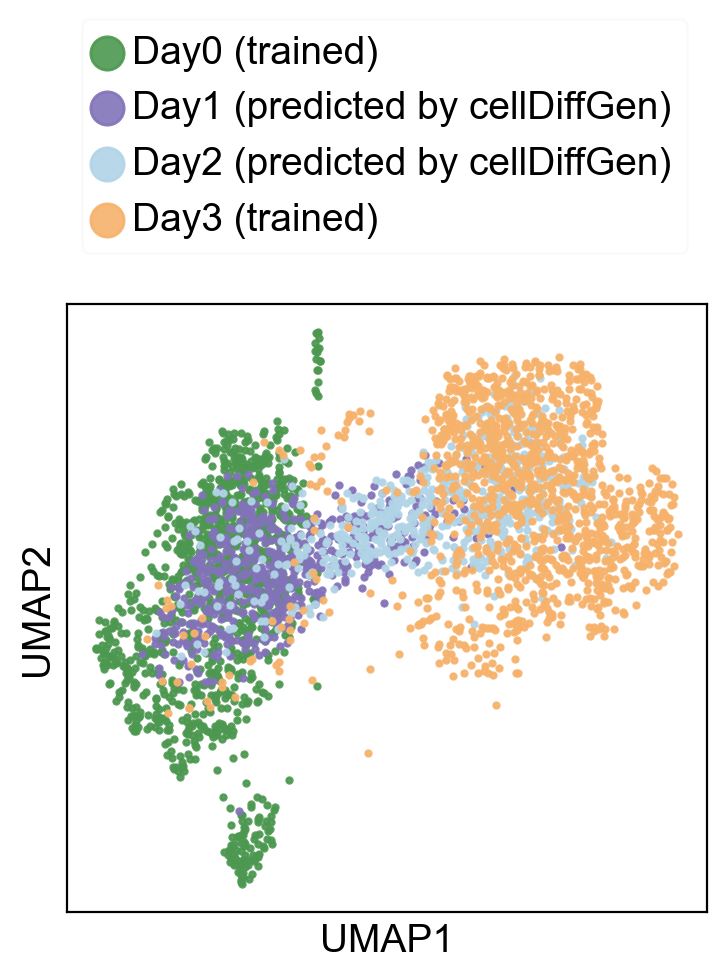

In [9]:

fig,ax = plt.subplots(figsize=(4.1, 4))
X_umap = interp_all_ann.obsm["X_umap"]

mask_0 = ((interp_all_ann.obs["day_types"] == 0) &
    (interp_all_ann.obs["class_types"] == "1"))
mask_1 = ((interp_all_ann.obs["day_types"] == 1) &
    (interp_all_ann.obs["class_types"] == "3"))
mask_2 = ((interp_all_ann.obs["day_types"] == 2) &
    (interp_all_ann.obs["class_types"] == "3"))
mask_3 = ((interp_all_ann.obs["day_types"] == 3) &
    (interp_all_ann.obs["class_types"] == "1"))

mask_ground_truth = interp_all_ann.obs["class_types"] == "2"

plt.scatter(
    X_umap[mask_0,0],
    X_umap[mask_0,1],
    c="#4C9850",
    s=4,
    alpha=0.9,
    label="Day0 (trained)"
)
plt.scatter(
    X_umap[mask_1,0],
    X_umap[mask_1,1],
    c="#8273B8",
    s=4,
    alpha=0.9,
    label="Day1 (predicted by cellDiffGen)"
)
plt.scatter(
    X_umap[mask_2,0],
    X_umap[mask_2,1],
    c="#B1D4E7",
    s=4,
    alpha=0.9,
    label="Day2 (predicted by cellDiffGen)"
)
plt.scatter(
    X_umap[mask_3,0],
    X_umap[mask_3,1],
    c="#F6B26B",
    s=4,
    alpha=0.9,
    label="Day3 (trained)"
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)
ax.set_xticks([])
ax.set_yticks([])
ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.0,1.5),
    markerscale=6,
    scatterpoints=1,
    prop={"size": 14, "weight": "bold"},
    frameon=True,
    facecolor="white",
    edgecolor="lightgray",
    framealpha=0.1
)
#plt.axis("off")
# plt.title("combined umap marked training data")
fig.savefig(os.path.join(f"figure3.pdf"), bbox_inches="tight")
plt.show()


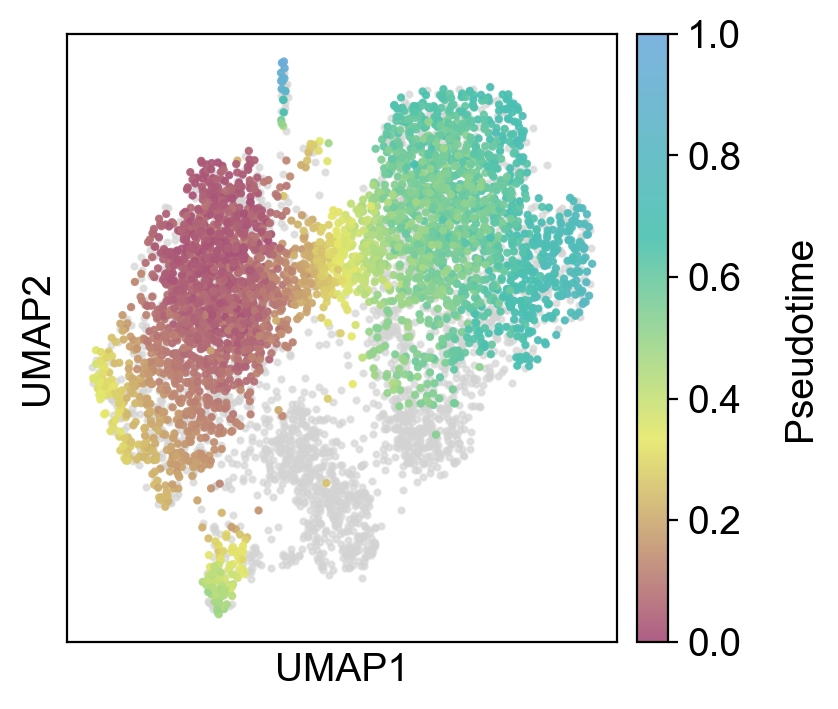

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(4.3, 4))

X_umap = interp_all_ann.obsm["X_umap"]
obs = interp_all_ann.obs

mask_0 = (obs["day_types"] == 0) & (obs["class_types"] == "1")
mask_1 = (obs["day_types"] == 1) & (obs["class_types"] == "3")
mask_2 = (obs["day_types"] == 2) & (obs["class_types"] == "3")
mask_3 = (obs["day_types"] == 3) & (obs["class_types"] == "1")

mask_show = (mask_0 | mask_1 | mask_2 | mask_3).to_numpy()

pseudotime = obs["dpt_pseudotime"].to_numpy()
mask_color = mask_show & np.isfinite(pseudotime)

my_cmap = LinearSegmentedColormap.from_list(
    "my_pseudotime",
    ["#A64D79", "#E6E86A", "#4AC1B0", "#6FABDC"]
)

# Other cells in gray
ax.scatter(
    X_umap[~mask_color, 0],
    X_umap[~mask_color, 1],
    c="lightgray",
    s=4,
    alpha=0.6
)

# Selected cells colored by pseudotime
points = ax.scatter(
    X_umap[mask_color, 0],
    X_umap[mask_color, 1],
    c=pseudotime[mask_color],
    cmap=my_cmap,
    vmin=0,
    vmax=1,
    s=4,
    alpha=0.9
)

cbar = fig.colorbar(points, ax=ax, pad=0.03)
cbar.set_label("Pseudotime", rotation=90, labelpad=15)

ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)

ax.set_xticks([])
ax.set_yticks([])

fig.savefig("figure4.pdf", bbox_inches="tight")
plt.show()